#Haremos en el notebook 05?

1. Cargar los datos preparados y las matrices de entrenamiento y prueba.
2. Entrenar una Regresión Logística.
3. Entrenar un Random Forest.
4. Comparar los primeros resultados.
5. Guardar los modelos entrenados.

Cargar los datos en el notebook 05

In [1]:
import pandas as pd
import numpy as np
import joblib
import os

# Cargar datos preparados
datos = joblib.load("../models/datos_entrenamiento.joblib")

X_train = datos["X_train"]
X_test = datos["X_test"]
y_train = datos["y_train"]
y_test = datos["y_test"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (3498, 1545)
Prueba: (288, 1545)


#Verificar los datos

In [2]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDistribución del objetivo en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

print("\nDistribución del objetivo en prueba:")
print(y_test.value_counts(normalize=True).round(3))

X_train: (3498, 1545)
X_test: (288, 1545)

y_train: (3498,)
y_test: (288,)

Distribución del objetivo en entrenamiento:
homeWin
1    0.572
0    0.428
Name: proportion, dtype: float64

Distribución del objetivo en prueba:
homeWin
1    0.628
0    0.372
Name: proportion, dtype: float64


Las matrices tienen las dimensiones esperadas.



Cada partido tiene su etiqueta correspondiente.



La distribución de victorias locales y visitantes está disponible para evaluar el modelo.

Primer modelo: Regresión Logística
Vamos a utilizar Regresión Logística como nuestro primer modelo de clasificación binaria.

Nuestro objetivo será predecir:
- 1: gana el equipo local.
- 0: gana el equipo visitante.

In [3]:
from sklearn.linear_model import LogisticRegression

# Crear el modelo
modelo_logistico = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Entrenar
modelo_logistico.fit(X_train, y_train)

print("Regresión Logística entrenada correctamente.")

Regresión Logística entrenada correctamente.


¿Qué estamos haciendo?
- max_iter=2000: permite más iteraciones para que el algoritmo encuentre una solución.
- random_state=42: establece una semilla reproducible.
- .fit(): entrena el modelo utilizando los datos de entrenamiento.

#Generar predicciones

In [4]:
# Realizar predicciones sobre los datos de prueba
y_pred_logistica = modelo_logistico.predict(X_test)

# Mostrar las primeras 20 predicciones
print("Primeras 20 predicciones:")
print(y_pred_logistica[:20])

Primeras 20 predicciones:
[0 1 1 0 1 1 1 1 1 0 1 0 1 0 1 1 1 0 1 1]


Esto genera las predicciones:
- 1: victoria del equipo local.
- 0: victoria del equipo visitante.

#Calcular métricas de evaluación

In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred_logistica)
precision = precision_score(y_test, y_pred_logistica)
recall = recall_score(y_test, y_pred_logistica)
f1 = f1_score(y_test, y_pred_logistica)

print("EVALUACIÓN - REGRESIÓN LOGÍSTICA")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_logistica))

EVALUACIÓN - REGRESIÓN LOGÍSTICA
--------------------------------
Accuracy:  0.6806
Precision: 0.7051
Recall:    0.8453
F1-score:  0.7688

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.61      0.40      0.48       107
           1       0.71      0.85      0.77       181

    accuracy                           0.68       288
   macro avg       0.66      0.62      0.63       288
weighted avg       0.67      0.68      0.66       288



¿Qué mide cada métrica?

Métrica	Qué nos indica

Accuracy	Porcentaje total de predicciones correctas.
Precision	De los equipos locales que predijo como ganadores, cuántos ganaron realmente.

Recall	De todas las victorias locales reales, cuántas detectó.
F1-score	Equilibrio entre Precision y Recall.

Importante: como nuestro objetivo es predecir victorias locales (homeWin = 1), estas métricas se calculan tomando esa clase como positiva.

Compárteme los resultados y analizaremos qué tan bien está funcionando nuestro primer modelo antes de pasar a Random Forest.

Interpretación de resultados
Accuracy general
68.06 %



Precision (victoria local)
70.51 %

Recall (victoria local)
84.53 %

F1-score (victoria local)
76.88 %

Partidos evaluados
288



¿Qué significan estos resultados?
- Accuracy 68.06 %: acertó aproximadamente 196 de los 288 partidos.
- Precision 70.51 %: cuando predice que gana el equipo local, acierta aproximadamente 7 de cada 10 veces.
- Recall 84.53 %: detecta una gran parte de las victorias locales reales.
- F1-score 76.88 %: muestra un equilibrio razonable entre Precision y Recall para la clase local.

Matriz de confusión

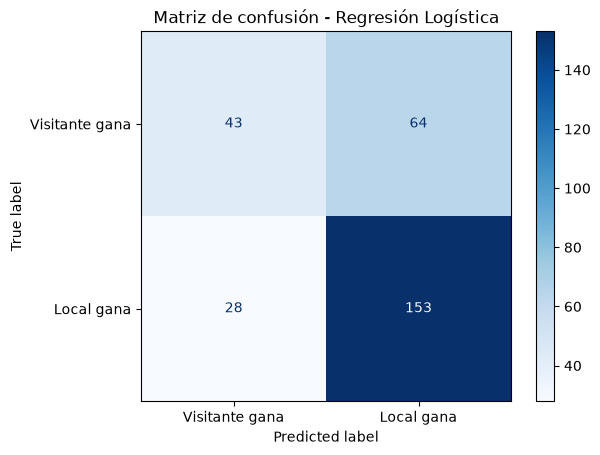

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Crear matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistica,
    display_labels=["Visitante gana", "Local gana"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Regresión Logística")
plt.show()

Esta matriz nos permitirá observar:
- Victorias locales correctamente identificadas.
- Victorias visitantes correctamente identificadas.
- Victorias locales confundidas con visitantes.
- Victorias visitantes confundidas con locales.

Interpretación de la matriz

Tomando los valores de tu resultado:
Resultado	Cantidad
Visitante gana y predijo visitante	43
Visitante gana y predijo local	64
Local gana y predijo visitante	28
Local gana y predijo local	153

¿Qué descubrimos?

- 43: identificó correctamente 43 victorias visitantes.
- 64: predijo victoria local cuando realmente ganó el visitante.
- 28: predijo victoria visitante cuando realmente ganó el local.
- 153: identificó correctamente 153 victorias locales.

196 predicciones correctas
 de 288 partidos.

Conclusión: el modelo reconoce bastante bien las victorias locales, pero tiene dificultades para detectar las victorias visitantes. Esto coincide con el Recall de 84.53 % para la clase 1 y 40.19 % para la clase 0.

#Random Forest

In [7]:
from sklearn.ensemble import RandomForestClassifier

# Crear modelo
modelo_random_forest = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    n_jobs=-1
)

# Entrenar modelo
modelo_random_forest.fit(X_train, y_train)

print("Random Forest entrenado correctamente.")

Random Forest entrenado correctamente.


Random Forest utiliza múltiples árboles de decisión y combina sus resultados para realizar una predicción.

Generar predicciones de Random Forest

In [8]:
# Generar predicciones
y_pred_rf = modelo_random_forest.predict(X_test)

print("Primeras 20 predicciones de Random Forest:")
print(y_pred_rf[:20])

Primeras 20 predicciones de Random Forest:
[0 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0]


Evaluar Random Forest

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular métricas
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("EVALUACIÓN - RANDOM FOREST")
print("--------------------------------")
print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_rf))

EVALUACIÓN - RANDOM FOREST
--------------------------------
Accuracy:  0.6285
Precision: 0.6729
Recall:    0.7956
F1-score:  0.7291

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.50      0.35      0.41       107
           1       0.67      0.80      0.73       181

    accuracy                           0.63       288
   macro avg       0.59      0.57      0.57       288
weighted avg       0.61      0.63      0.61       288



Comparación de modelos

Métrica	=>Regresión Logística	Random Forest

Accuracy=>	68.06 %	62.85 %
Precision=>	70.51 %	67.29 %
Recall	=>84.53 %	79.56 %
F1-score=>	76.88 %	72.91 %

Mejor modelo hasta ahora
Regresión Logística

68.06 %
Accuracy en el conjunto de prueba.

¿Qué significa?
- Regresión Logística acertó aproximadamente 196 partidos.
- Random Forest acertó aproximadamente 181.
- Regresión Logística consiguió 15 aciertos adicionales.

Algo que debemos investigar

Random Forest obtuvo un Accuracy de 62.85 %, prácticamente igual al 62.8 % que conseguiríamos prediciendo siempre que gana el equipo local.

Esto significa que, con su configuración actual, Random Forest no está aportando una mejora apreciable frente a esa predicción básica.

No significa que Random Forest sea un mal algoritmo. Puede necesitar ajustes.

Paso 12. Crear una tabla comparativa en nuestro notebook

Vamos a guardar los resultados de ambos modelos en una tabla para documentar el experimento.

In [10]:
comparacion = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_rf
    ],
    "Precision": [
        precision,
        precision_rf
    ],
    "Recall": [
        recall,
        recall_rf
    ],
    "F1-score": [
        f1,
        f1_rf
    ]
})

comparacion = comparacion.set_index("Modelo")

comparacion.round(4)

,Accuracy,Precision,Recall,F1-score
Modelo,,,,
Regresión Logística,0.6806,0.7051,0.8453,0.7688
Random Forest,0.6285,0.6729,0.7956,0.7291


continuar con este orden:
1. Comparar visualmente ambos modelos.
2. Ajustar los hiperparámetros de Random Forest.
3. Probar otros algoritmos, como Gradient Boosting.
4. Seleccionar el mejor modelo según las métricas.
5. Guardar el modelo definitivo.

Ajustar Random Forest

In [11]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

# Configuraciones que vamos a explorar
parametros = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced"]
}

# Modelo base
rf_base = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Búsqueda de hiperparámetros
busqueda_rf = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=parametros,
    n_iter=12,
    cv=3,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Buscar usando solamente entrenamiento
busqueda_rf.fit(X_train, y_train)

print("Mejores parámetros:")
print(busqueda_rf.best_params_)

print("\nMejor F1 macro en validación cruzada:")
print(round(busqueda_rf.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores parámetros:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': None}

Mejor F1 macro en validación cruzada:
0.4251


Evaluar el Random Forest optimizado

In [12]:
modelo_rf_optimizado = busqueda_rf.best_estimator_

y_pred_rf_optimizado = modelo_rf_optimizado.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf_optimizado))
print("Precision:", precision_score(y_test, y_pred_rf_optimizado))
print("Recall:", recall_score(y_test, y_pred_rf_optimizado))
print("F1-score:", f1_score(y_test, y_pred_rf_optimizado))

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_rf_optimizado))

Accuracy: 0.6284722222222222
Precision: 0.6284722222222222
Recall: 1.0
F1-score: 0.7718550106609808

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       107
           1       0.63      1.00      0.77       181

    accuracy                           0.63       288
   macro avg       0.31      0.50      0.39       288
weighted avg       0.39      0.63      0.49       288



c:\Users\maxwe\OneDrive\Desktop\EntrenaAI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\maxwe\OneDrive\Desktop\EntrenaAI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\maxwe\OneDrive\Desktop\EntrenaAI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

Guardar nuestro modelo

In [14]:
import joblib
import os

# Crear carpeta de modelos
os.makedirs("../models", exist_ok=True)

# Guardar modelo seleccionado
joblib.dump(
    modelo_logistico,
    "../models/modelo_logistico.joblib"
)

print("Modelo de Regresión Logística guardado correctamente.")

Modelo de Regresión Logística guardado correctamente.


Guardar los resultados de los modelos

In [15]:
import os

# Crear carpeta de informes
os.makedirs("../reports", exist_ok=True)

# Guardar comparación de modelos
comparacion.to_csv(
    "../reports/comparacion_modelos.csv"
)

print("Comparación de modelos guardada correctamente.")

Comparación de modelos guardada correctamente.


Guardar la matriz de confusión

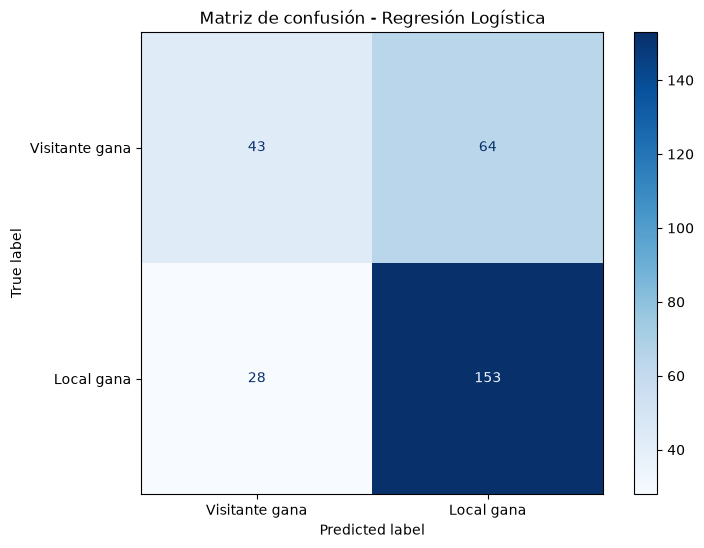

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistica,
    display_labels=["Visitante gana", "Local gana"],
    cmap="Blues",
    ax=ax
)

ax.set_title("Matriz de confusión - Regresión Logística")

plt.savefig(
    "../reports/matriz_confusion_logistica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()